# Qu'est-ce qui fait le prix d'un logement dans la métropole lilloise ?

**Question métier** : à quel prix un logement de la MEL s'échange-t-il *réellement*, et qu'est-ce qui
explique l'écart entre deux biens ? Pour un acheteur ou un conseiller, la vraie question est :
*ce bien est-il au prix du marché, compte tenu de ce qu'il est et de là où il est ?*

**Données** : *Demandes de valeurs foncières* (DVF, DGFiP), version géolocalisée d'Etalab : toutes les
ventes notariées 2021-2025 du Nord, restreintes aux 95 communes de la Métropole Européenne de Lille
(liste officielle, API Géo). Des ventes réelles, pas des annonces.

**Méthode** : nettoyage documenté → exploration → **régression hédonique** (log-prix expliqué par les
caractéristiques, à quartier et trimestre fixés) → validation sur des ventes non vues → tests.

Toutes les cartes et tables sont agrégées par quartier : aucune adresse n'est affichée (conditions de
réutilisation de DVF).

In [1]:
import sys
sys.path.insert(0, "../src")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image
import model as M

pd.set_option("display.float_format", "{:,.1f}".format)
df = M.load()
print(f"{len(df):,} ventes exploitables, {df['commune'].nunique()} communes, "
      f"{df['date'].min():%m/%Y} → {df['date'].max():%m/%Y}")

73,271 ventes exploitables, 95 communes, 01/2021 → 12/2025


## 1. Des données brutes aux ventes exploitables

Le piège central de DVF : **une ligne n'est pas une vente**. Le fichier compte une ligne par lot et par
parcelle, et `valeur_fonciere` est le prix de la *mutation entière*, répété sur chaque ligne. Une vente
de 3 appartements apparaît 3 fois avec le prix total : la diviser par la surface d'un seul appartement
triplerait son prix au m². On ne garde donc que les ventes d'**un seul logement**. Chaque filtre est
compté (`docs/entonnoir.csv`) :

In [2]:
pd.read_csv("../docs/entonnoir.csv")

,etape,ventes,ecartees
0,"Mutations DVF dans la MEL, 2021-2025",109808,0
1,"Ventes simples (hors VEFA, échanges, adjudicat...",100060,9748
2,"Un seul logement vendu (dépendances admises, p...",76689,23371
3,"Prix, surface, pièces et géolocalisation rense...",76118,571
4,"Biens résidentiels plausibles (10-400 m², 1-12...",75754,364
5,"Prix au m² hors 1 % extrêmes de chaque côté, p...",74242,1512
6,Hors résidences étudiantes/de services vendues...,73271,971


**Deux anomalies trouvées en explorant, et traitées :**

- **Résidences étudiantes vendues lot par lot.** En 2021, la médiane des appartements de Villeneuve-d'Ascq
  montait à 4 558 €/m² contre ~2 400 €/m² les autres années : 200 studios de 16-20 m² vendus au même
  point GPS, un produit d'investissement (LMNP), pas le marché résidentiel. Règle : ≥ 5 studios
  (surface médiane < 30 m²) au même point la même année sont écartés (971 ventes, 1,3 %).
- **Un immeuble qui se fait passer pour un quartier.** Une cellule de Marcq-en-Barœul ressortait à +87 % :
  30 de ses 32 ventes concernent un seul immeuble récent. Toute cellule dont un immeuble fait plus de
  50 % des ventes est signalée (`fiable = False`) et exclue de la carte.

À l'inverse, le quartier du Blanc-Riez à Wattignies ressort à −52 % sur 128 ventes réparties sur
plusieurs immeubles et 5 ans : c'est une réalité de marché (quartier prioritaire), pas une anomalie.

## 2. Exploration

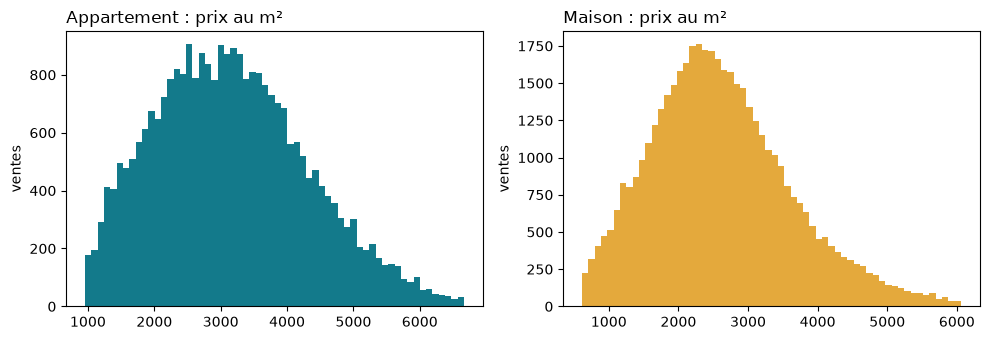

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (t, c) in zip(axes, (("Appartement", "#137A8B"), ("Maison", "#E4A93C"))):
    df.loc[df["type"] == t, "prix_m2"].plot.hist(bins=60, ax=ax, color=c)
    ax.set_title(f"{t} : prix au m²", loc="left"); ax.set_ylabel("ventes")
plt.tight_layout()

In [4]:
top = df["commune"].value_counts().head(10).index
(df[df["commune"].isin(top)]
   .pivot_table(index="commune", columns="type", values="prix_m2", aggfunc="median")
   .sort_values("Appartement", ascending=False).round(0))

type,Appartement,Maison
commune,,
Lille,"3,710.0","2,812.0"
Marcq-en-Barœul,"3,422.0","3,885.0"
La Madeleine,"3,200.0","3,659.0"
Lambersart,"3,059.0","3,618.0"
Croix,"2,542.0","2,494.0"
Villeneuve-d'Ascq,"2,492.0","3,059.0"
Wattrelos,"1,982.0","1,936.0"
Armentières,"1,900.0","1,900.0"
Roubaix,"1,892.0","1,467.0"


Le prix au m² varie du simple au double entre communes, et autant *à l'intérieur* de Lille. Une
médiane par commune ne peut donc pas servir d'estimation : c'est la référence naïve qu'il faut battre.

## 3. Le modèle hédonique

Un modèle par type de bien, estimé par MCO avec écarts-types robustes (HC3) :

$$\log(\text{prix}) = \beta_1 \log(\text{surface}) + \text{pièces} + \text{dépendance}\;[+\,\beta \log(1+\text{terrain})]
+ \underbrace{\alpha_{\text{quartier}}}_{\text{cellule} \approx 550\,\text{m}} + \underbrace{\gamma_{\text{trimestre}}}_{\text{conjoncture}} + \varepsilon$$

Les effets fixes quartier et trimestre font lire chaque coefficient *à emplacement et date identiques*.
Une cellule de moins de 30 ventes est regroupée avec le reste de sa commune.

In [5]:
pd.read_csv("../outputs/validation.csv")

,type,ventes_test,erreur_mediane_modele_pct,erreur_mediane_naive_pct,part_a_10pct_modele,part_a_10pct_naive
0,Appartement,5598,13.7,18.4,37.5,28.2
1,Maison,9055,17.6,20.1,29.4,26.3


**Validation sur 20 % de ventes non vues** (tirage aléatoire, graine fixe) contre la méthode naïve
« médiane €/m² de la commune et de l'année × surface » :

- Appartements : erreur médiane **13,7 %** contre 18,4 % → un quart d'erreur en moins ; 37,5 % des
  ventes estimées à ±10 % près (contre 28,2 %).
- Maisons : **17,6 %** contre 20,1 %. Gain plus modeste : l'état du bien, le DPE et les travaux, absents de
  DVF, pèsent bien plus sur une maison que sur un appartement (voir Limites).

## 4. Ce qui fait le prix, à emplacement et date identiques

In [6]:
c = pd.read_csv("../outputs/coefficients.csv")
c[["type", "variable", "coef", "ic95_bas", "ic95_haut", "p_value", "effet_pct"]].round(3)

,type,variable,coef,ic95_bas,ic95_haut,p_value,effet_pct
0,Appartement,C(pieces_c)[T.2],0.0,0.0,0.0,0.0,1.6
1,Appartement,C(pieces_c)[T.3],0.0,0.0,0.0,0.0,1.8
2,Appartement,C(pieces_c)[T.4],-0.0,-0.0,0.0,0.9,-0.1
3,Appartement,C(pieces_c)[T.5],-0.0,-0.0,0.0,1.0,-0.0
4,Appartement,C(pieces_c)[T.6],0.1,0.1,0.1,0.0,11.3
5,Appartement,log_surface,0.8,0.8,0.8,0.0,NaN
6,Appartement,dependance,0.1,0.1,0.1,0.0,7.6
7,Maison,C(pieces_c)[T.2],-0.0,-0.1,0.0,0.4,-3.1
8,Maison,C(pieces_c)[T.3],-0.0,-0.1,0.0,0.2,-4.4
9,Maison,C(pieces_c)[T.4],-0.0,-0.1,0.0,0.5,-2.4


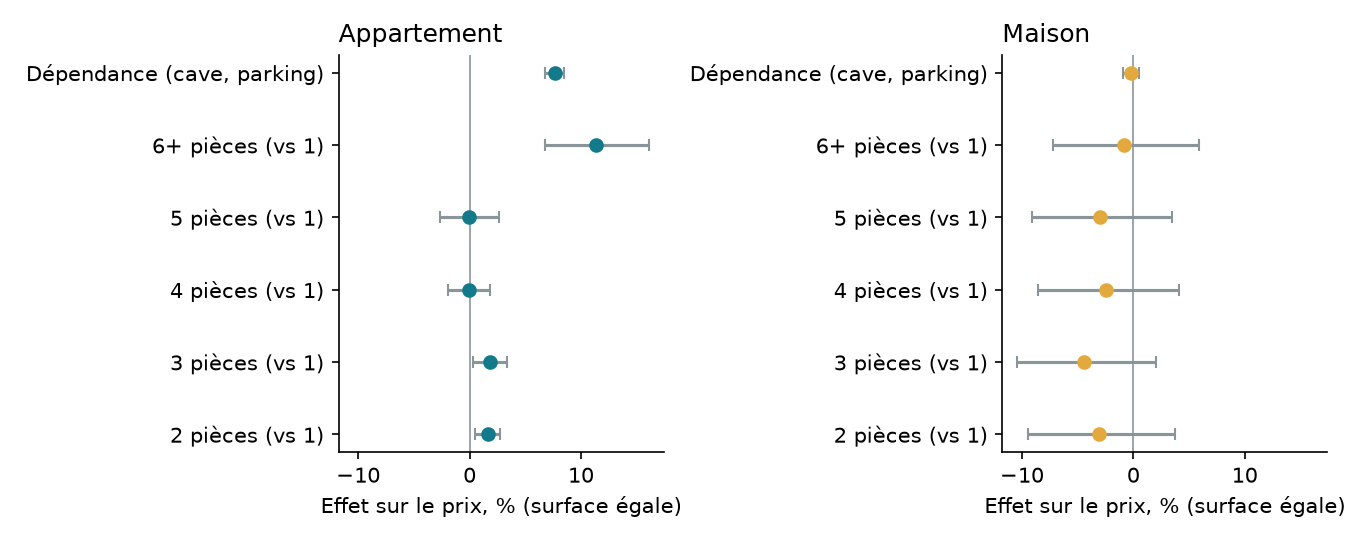

In [7]:
Image("../outputs/effets_caracteristiques.png")

- **Surface** : élasticité 0,79 (appartements) et 0,82 (maisons) < 1 → le prix au m² baisse quand la
  surface augmente. Doubler la surface multiplie le prix par ~1,73 et baisse le prix au m² d'environ 13 %.
- **Cave / parking** : **+7,6 %** sur un appartement (IC 95 % : +6,8 % à +8,5 %). Sur une maison :
  aucun effet mesurable (p = 0,54).
- **Nombre de pièces** : à surface égale, quasiment aucun effet. On paie des m², pas des cloisons ; seuls
  les 6 pièces et plus (grands appartements anciens) se vendent ~11 % plus cher.
- **Terrain** (maisons) : doubler (1 + terrain) ajoute ~5 % au prix.

## 5. La conjoncture : un indice de prix à qualité constante

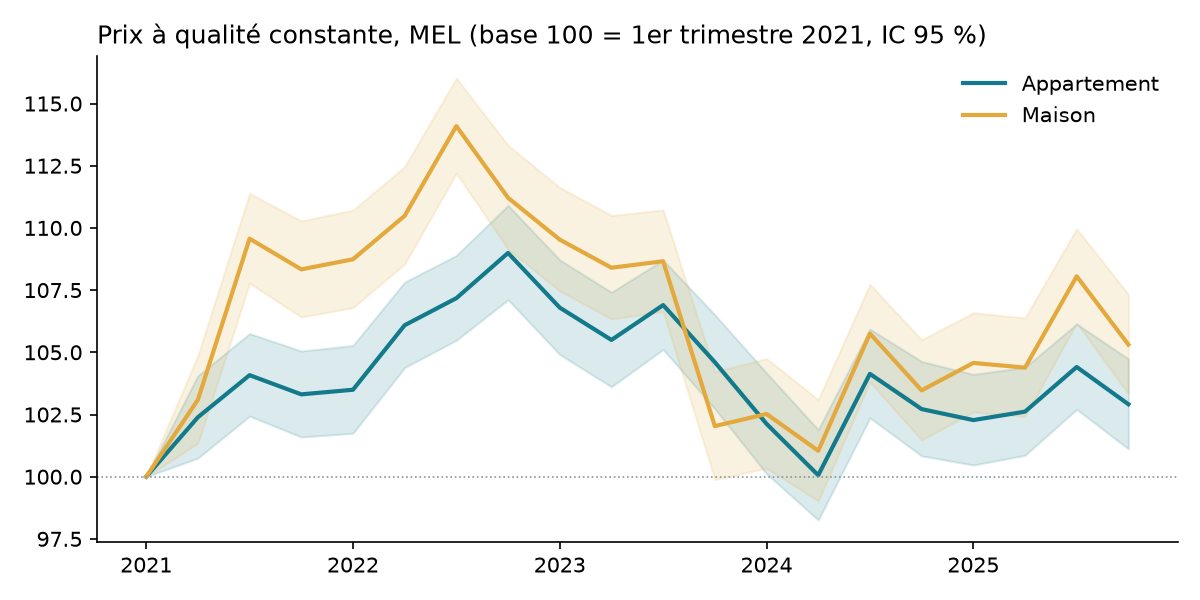

In [8]:
Image("../outputs/indice_prix.png")

In [9]:
pd.read_csv("../outputs/test_hausse_taux.csv")

,type,ecart_2024_vs_2022_pct,ic95_bas_pct,ic95_haut_pct,p_value
0,Appartement,-3.9,-4.8,-3.0,0.0
1,Maison,-7.1,-8.0,-6.2,0.0


Un indice brut mélange l'évolution des prix et celle des biens vendus (si moins de grandes maisons se
vendent, la médiane baisse sans que les prix bougent). Ici les effets trimestre sont estimés *à bien
égal*.

**Test** : H0 « le prix à qualité constante est le même en 2024 qu'en 2022 ». Rejetée nettement :
**−3,9 %** pour les appartements (IC 95 % : −4,8 % à −3,0 %) et **−7,1 %** pour les maisons
(−8,0 % à −6,2 %), p < 10⁻¹⁷. C'est la trace de la hausse des taux de 2022-2023 ; le marché repart
modestement en 2025 (+3 % et +5 % par rapport à début 2021, fin 2025).

## 6. Ce que coûte chaque quartier, à bien égal

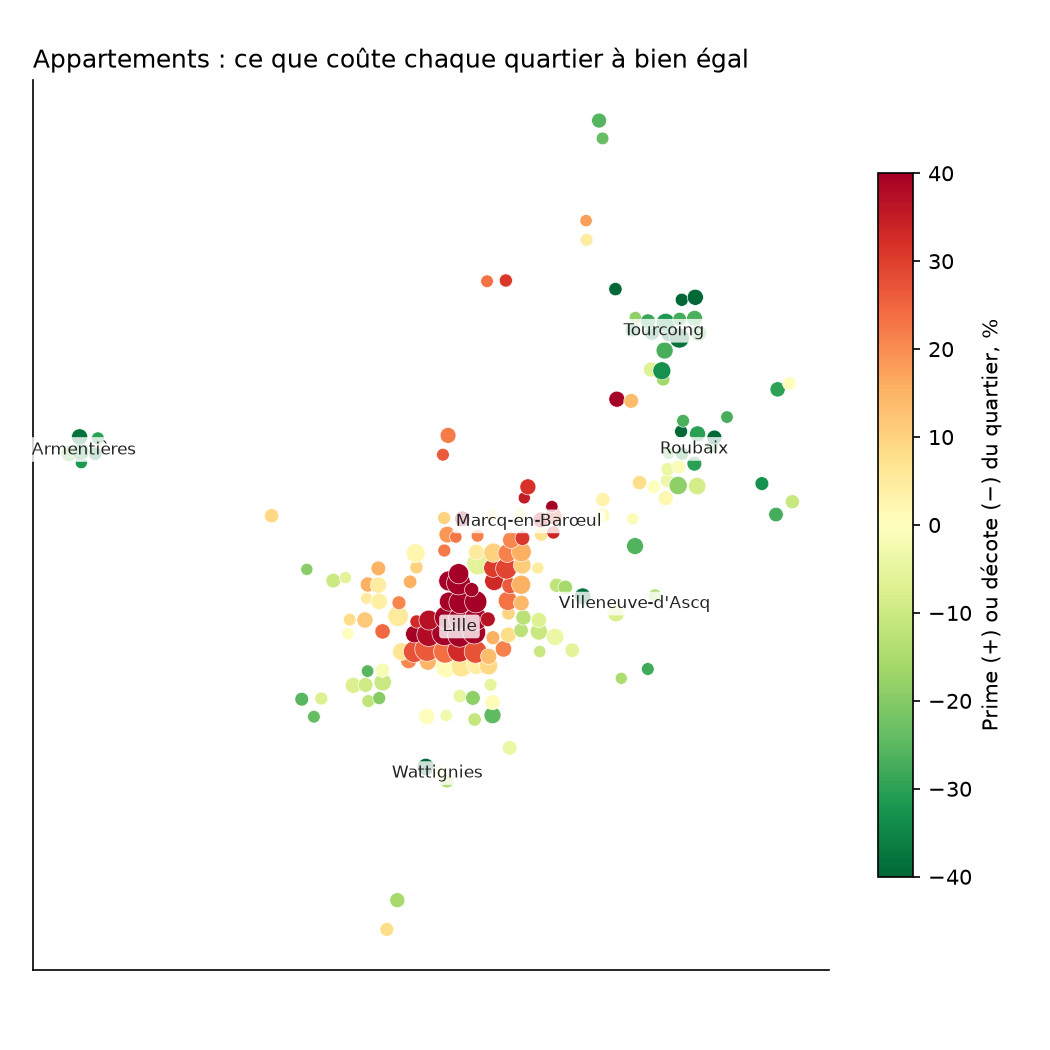

In [10]:
Image("../outputs/carte_quartiers_appartements.png")

In [11]:
q = pd.read_csv("../outputs/quartiers.csv")
q = q[q["fiable"]]
q.groupby("type")["prime_pct"].describe(percentiles=[.1, .5, .9]).round(0)

,count,mean,std,min,10%,50%,90%,max
type,,,,,,,,
Appartement,181.0,3.0,27.0,-52.0,-30.0,1.0,37.0,69.0
Maison,543.0,2.0,26.0,-54.0,-29.0,-1.0,39.0,80.0


**L'emplacement pèse beaucoup plus que la conjoncture.** Entre un quartier du 10ᵉ et du 90ᵉ centile,
le même bien coûte de −30 % à +37 % par rapport au quartier médian, soit un écart de 1 à 2. Le cycle
des taux, lui, a fait monter les prix d'au plus 9 % (appartements) et 14 % (maisons) avant le repli.

## 7. Limites

- **Pas d'information sur l'état du bien** : DPE, travaux, étage, exposition, ascenseur sont absents de
  DVF. C'est la principale source d'erreur restante, surtout pour les maisons. Extension possible :
  jointure avec la base DPE de l'ADEME (par adresse), au prix d'une perte de couverture.
- **Neuf hors VEFA non identifiable** : un immeuble récent revendu en bloc gonfle sa cellule (signalée,
  pas corrigée).
- **Corrélation, pas causalité** : « +7,6 % pour une cave/un parking » est un écart à caractéristiques
  observées égales ; les biens avec dépendance peuvent aussi être de meilleure qualité sur des points
  non observés.
- **Grille fixe** : les cellules de 550 m ne suivent pas les frontières réelles des quartiers (IRIS).